# Machine Learning Assignment: Phân Tích & Mô Hình Hóa Bất Động Sản King County

**Bộ dữ liệu**: `data.csv` (King County Housing Sales)  
**Mục tiêu bài tập**: Thực hiện trọn vẹn 5 bài toán được chỉ định trong đề bài ([Assignment Machine learning.docx]):
1. **Bài 1 (Supervised Regression)**: Dự đoán giá nhà (`price`)
2. **Bài 2 (Supervised Regression)**: Dự đoán diện tích nhà (`sqft_living`)
3. **Bài 3 (Supervised Classification)**: Phân loại nhà giá cao / thấp (Target nhị phân từ `price`)
4. **Bài 4 (Unsupervised Clustering)**: Phân nhóm các căn nhà tương tự nhau theo đa thuộc tính (K-Means, PCA 2D)
5. **Bài 5 (Unsupervised Clustering)**: Phân khúc nhà theo giá và diện tích (K-Means 2D)

**Nguyên tắc khoa học & kỹ thuật xuyên suốt**:
- Triệt tiêu đa cộng tuyến hoàn hảo: $sqft\_living = sqft\_above + sqft\_basement$.
- Tôn trọng ranh giới thiết kế bài toán (Problem Formulation) và ngăn ngừa rò rỉ dữ liệu (No Data Leakage).
- Đánh giá đồng nhất bằng 5-Fold Cross-Validation và so sánh đối chứng với Dummy Baseline.
- Minh bạch giữa tiêu chuẩn toán học và quyết định nghiệp vụ kinh doanh.

---
## Phần 0: Khám Phá Dữ Liệu Sâu (Deep EDA) & Xử Lý Dị Biệt

Trước khi đưa dữ liệu vào bất kỳ mô hình học máy nào, ta cần kiểm tra toàn diện chất lượng dữ liệu:
- Kiểm tra kiểu dữ liệu, các giá trị thiếu (missing values) hiển thị và ẩn.
- Phát hiện các dị biệt cực đoan (Anomalies / Data entry errors).
- Xây dựng đặc trưng mới (Feature Engineering) để bảo toàn thông tin mà không gây đa cộng tuyến.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 100

print("Import thư viện cơ bản thành công!")

Import thư viện cơ bản thành công!


### 0.1. Đọc dữ liệu và rà soát cấu trúc ban đầu

In [2]:
df_raw = pd.read_csv('data.csv')
print(f"Kích thước ban đầu: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")
print("\nThông tin kiểu dữ liệu:")
print(df_raw.info())
print("\nSố lượng giá trị thiếu (Null/NaN) trên từng cột:")
print(df_raw.isnull().sum())
print(f"Số dòng trùng lặp hoàn toàn: {df_raw.duplicated().sum()}")

Kích thước ban đầu: 4600 dòng, 18 cột

Thông tin kiểu dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   int64  
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   ob

### 0.2. Phát hiện và xử lý các điểm dị biệt nghiêm trọng (Data Anomalies)

Khi kiểm tra thống kê mô tả, ta phát hiện 3 vấn đề nhập liệu nghiêm trọng:
1. **49 căn nhà có `price == 0.0`**: Đây là các giá trị missing ẩn (nhà không thể có giá $0). Cần loại bỏ vì giá trị này sẽ bóp méo toàn bộ các phép biến đổi $\log$ và kéo lệch các mô hình hồi quy / phân cụm.
2. **2 căn nhà có diện tích lớn ($> 3.000\text{ sqft}$) nhưng `bedrooms == 0` và `bathrooms == 0`**: Các căn nhà này có diện tích và giá bán lớn hơn 1 triệu USD nhưng không có phòng ngủ hay phòng tắm (lỗi ghi nhận hồ sơ). Cần loại bỏ.
3. **Căn nhà dị biệt tại Kent (`price == 26.590.000 USD`)**: Căn nhà này có diện tích chỉ $1.180\text{ sqft}$, 3 phòng ngủ tại khu vực bình dân (Kent), nhưng giá bán ghi nhận lên tới $26.59$ triệu USD (gấp 50 lần mức trung bình khu vực). Đây là lỗi gõ thừa số 0 (Typo) cực đoan. Việc giữ lại điểm đòn bẩy (high-leverage point) này sẽ kéo lệch nghiêm trọng các mô hình tuyến tính và phép chuẩn hóa.

In [3]:
# 1. Kiểm tra số căn price == 0
zero_price_count = (df_raw['price'] == 0).sum()
print(f"Số căn nhà có giá bằng 0: {zero_price_count}")

# 2. Kiểm tra căn có bedrooms == 0 hoặc bathrooms == 0
zero_rooms = df_raw[(df_raw['bedrooms'] == 0) | (df_raw['bathrooms'] == 0)]
print(f"Số căn nhà có 0 phòng ngủ hoặc 0 phòng tắm: {len(zero_rooms)}")
print(zero_rooms[['price', 'bedrooms', 'bathrooms', 'sqft_living', 'city']])

# 3. Kiểm tra ngoại lai giá cực đoan
extreme_prices = df_raw[df_raw['price'] > 10000000]
print(f"\nCác căn nhà có giá > 10 triệu USD:")
print(extreme_prices[['price', 'bedrooms', 'bathrooms', 'sqft_living', 'city']])

# TIẾN HÀNH LỌC DỮ LIỆU SẠCH
df_clean = df_raw[
    (df_raw['price'] > 0) & 
    (df_raw['bedrooms'] > 0) & 
    (df_raw['bathrooms'] > 0) &
    (df_raw['price'] < 20000000)  # Loại bỏ căn typo 26.59M ở Kent
].copy().reset_index(drop=True)

print(f"\nSố dòng sau khi làm sạch ngoại lai: {len(df_clean)} dòng (Đã loại bỏ {len(df_raw) - len(df_clean)} dòng dị biệt)")

Số căn nhà có giá bằng 0: 49
Số căn nhà có 0 phòng ngủ hoặc 0 phòng tắm: 2
          price  bedrooms  bathrooms  sqft_living     city
2365  1095000.0         0        0.0         3064  Seattle
3209  1295648.0         0        0.0         4810  Redmond

Các căn nhà có giá > 10 triệu USD:
           price  bedrooms  bathrooms  sqft_living     city
4346  12899000.0         3        2.5         2190  Seattle
4350  26590000.0         3        2.0         1180     Kent

Số dòng sau khi làm sạch ngoại lai: 4548 dòng (Đã loại bỏ 52 dòng dị biệt)


### 0.3. Feature Engineering & Quyết định về các Cột Chuỗi

1. **Xử lý đa cộng tuyến hoàn hảo**:
   - Ta kiểm tra phương trình: $sqft\_living = sqft\_above + sqft\_basement$.
   - Vì tổng diện tích tầng nổi và tầng hầm đúng chính xác $100\%$ bằng diện tích sử dụng, đưa cả 3 vào mô hình tuyến tính sẽ gây đa cộng tuyến hoàn hảo.
   - Để không làm mất thông tin hữu ích về tầng hầm, ta tạo biến nhị phân: `has_basement = (sqft_basement > 0).astype(int)`.
2. **Xử lý cột `yr_renovated`**:
   - Cột `yr_renovated` có hơn $60\%$ giá trị là $0$ (chưa từng cải tạo). Ta tạo biến nhị phân: `is_renovated = (yr_renovated > 0).astype(int)`.
3. **Loại bỏ các cột không sử dụng**:
   - `country`: 100% là "USA" (hằng số, phương sai = 0).
   - `date`: Giao dịch chỉ thu thập trong 3 tháng hè 2014, không đủ chu kỳ mùa vụ.
   - `street`: Hơn 4.500 địa chỉ riêng lẻ, gây quá tải số chiều.
   - `statezip`: 77 mã bưu chính trùng lặp phân vùng địa lý với `city`.
   - `city`: 44 thành phố, giữ lại làm đại diện vị trí đắc địa và mã hóa bằng One-Hot Encoding.
4. **Biến đổi Log đối với các biến lệch phải (Skewed Features)**:
   - `price`, `sqft_living`, `sqft_lot` có phân phối lệch phải cực đoan. Ta áp dụng $\log(1 + x)$ để đưa về phân phối tiệm cận chuẩn Gaussian.

Số dòng thỏa mãn sqft_living == sqft_above + sqft_basement: 4548 / 4548


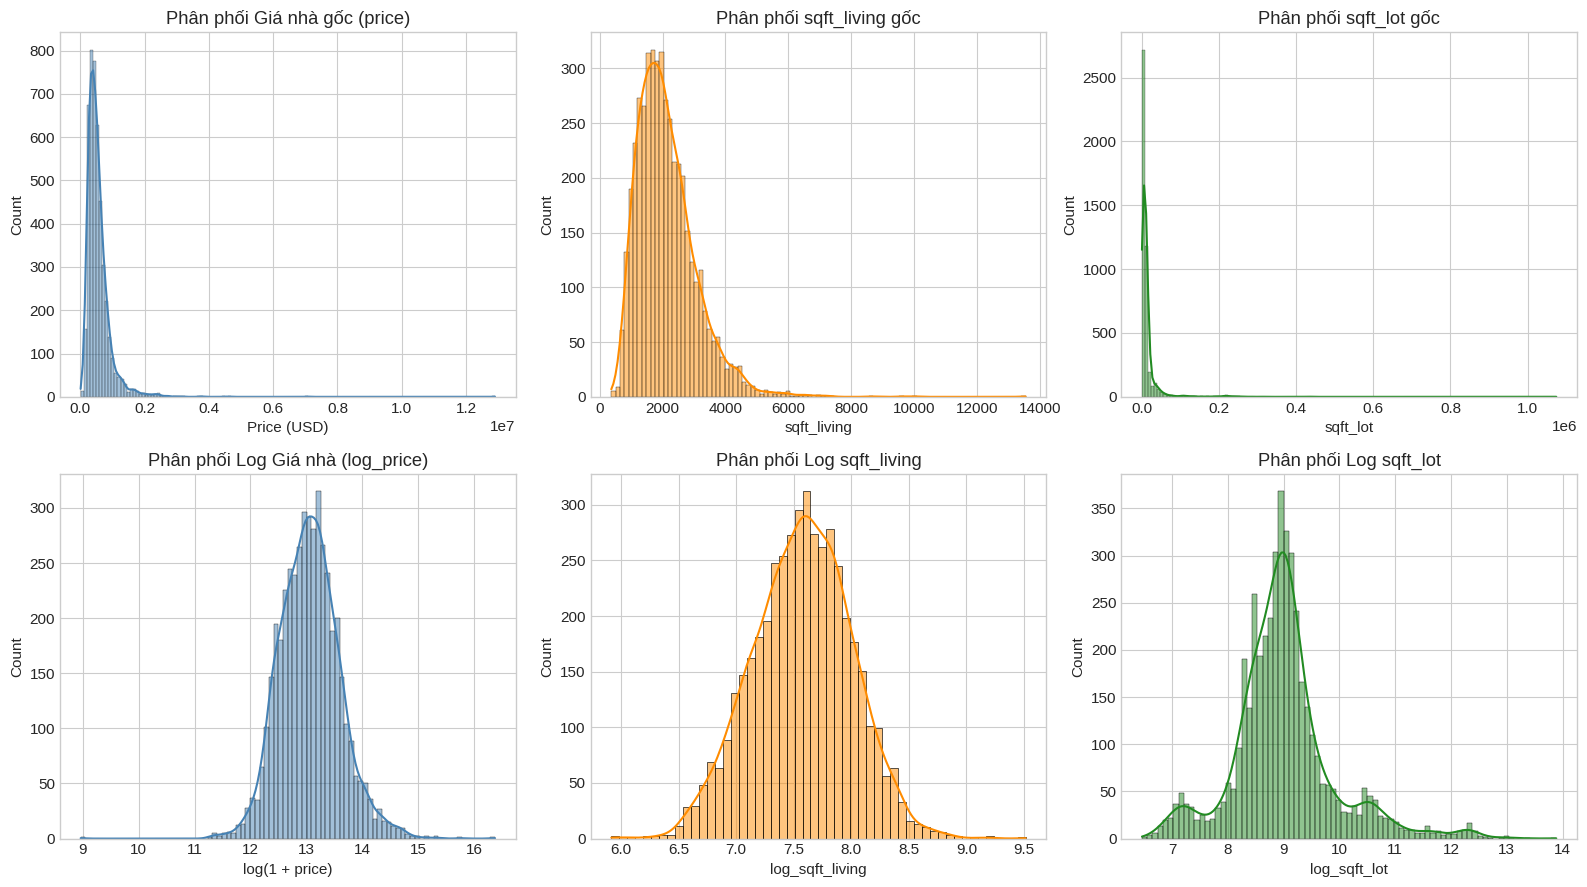

In [4]:
# Kiểm tra quan hệ giải phẫu diện tích
exact_diff = (df_clean['sqft_living'] - (df_clean['sqft_above'] + df_clean['sqft_basement'])).abs()
print(f"Số dòng thỏa mãn sqft_living == sqft_above + sqft_basement: {(exact_diff == 0).sum()} / {len(df_clean)}")

# Tạo các đặc trưng mới
df_clean['has_basement'] = (df_clean['sqft_basement'] > 0).astype(int)
df_clean['is_renovated'] = (df_clean['yr_renovated'] > 0).astype(int)
df_clean['log_sqft_lot'] = np.log1p(df_clean['sqft_lot'])
df_clean['log_sqft_living'] = np.log1p(df_clean['sqft_living'])
df_clean['log_price'] = np.log1p(df_clean['price'])

# Trực quan hóa phân phối trước và sau Log Transformation
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.histplot(df_clean['price'], kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Phân phối Giá nhà gốc (price)')
axes[0, 0].set_xlabel('Price (USD)')

sns.histplot(df_clean['sqft_living'], kde=True, ax=axes[0, 1], color='darkorange')
axes[0, 1].set_title('Phân phối sqft_living gốc')

sns.histplot(df_clean['sqft_lot'], kde=True, ax=axes[0, 2], color='forestgreen')
axes[0, 2].set_title('Phân phối sqft_lot gốc')

sns.histplot(df_clean['log_price'], kde=True, ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Phân phối Log Giá nhà (log_price)')
axes[1, 0].set_xlabel('log(1 + price)')

sns.histplot(df_clean['log_sqft_living'], kde=True, ax=axes[1, 1], color='darkorange')
axes[1, 1].set_title('Phân phối Log sqft_living')

sns.histplot(df_clean['log_sqft_lot'], kde=True, ax=axes[1, 2], color='forestgreen')
axes[1, 2].set_title('Phân phối Log sqft_lot')

plt.tight_layout()
plt.show()

---
## Phần 1: Bài Toán 1 (Supervised Regression) - Dự Đoán Giá Nhà (`price`)

### 1.1. Thiết kế bài toán
- **Mục tiêu**: Dự đoán giá trị căn nhà ($price$) dựa trên thuộc tính kiến trúc, chất lượng và vị trí.
- **Biến mục tiêu**: $y = \log(1 + price)$ (giúp mô hình tối ưu theo hàm phân phối tiệm cận chuẩn và giảm tác động của các căn giá siêu cao).
- **Tập biến độc lập $X$**:
  - Biến số: `bedrooms`, `bathrooms`, `sqft_living`, `log_sqft_lot`, `floors`, `waterfront`, `view`, `condition`, `yr_built`, `is_renovated`, `has_basement`.
  - Biến phân loại: `city` (được One-Hot Encode).
  - *Lưu ý*: Loại bỏ hoàn toàn `sqft_above` và `sqft_basement` để triệt tiêu đa cộng tuyến hoàn hảo.
- **Quy trình đánh giá**:
  - Dùng **5-Fold Cross-Validation** đồng nhất để đo $R^2$ (log), $RMSE$ (log), và $MAE$ (USD thực tế).
  - So sánh đối chứng: **DummyRegressor** (dự đoán trung bình - mốc sàn), **Ridge Regression** (mô hình tuyến tính có điều chuẩn), và **RandomForestRegressor** (mô hình phi tuyến học tương tác biến).
  - Đo $MAE$ trên thang USD thực tế bằng công thức:
    $$MAE = \frac{1}{n} \sum |y_{true\_USD} - \text{expm1}(\hat{y}_{pred\_log})|$$

In [5]:
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Định nghĩa tập thuộc tính
feat1_num = ['bedrooms', 'bathrooms', 'sqft_living', 'log_sqft_lot', 'floors', 
             'waterfront', 'view', 'condition', 'yr_built', 'is_renovated', 'has_basement']
feat1_cat = ['city']

X1 = df_clean[feat1_num + feat1_cat]
y1_log = df_clean['log_price']
y1_usd = df_clean['price']

# Bộ tiền xử lý riêng cho Bài toán 1
prep1 = ColumnTransformer([
    ('num', StandardScaler(), feat1_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), feat1_cat)
])

# Thiết lập 5-Fold Cross-Validation
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

models1 = {
    'Dummy (Baseline)': DummyRegressor(strategy='mean'),
    'Ridge Regression': Pipeline([('prep', prep1), ('model', Ridge(alpha=1.0))]),
    'Random Forest': Pipeline([('prep', prep1), ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
}

# Đánh giá 5-Fold CV
results1 = []
for name, m in models1.items():
    r2_folds = []
    rmse_folds = []
    mae_usd_folds = []
    
    for train_idx, val_idx in cv5.split(X1, y1_log):
        X_tr, X_val = X1.iloc[train_idx], X1.iloc[val_idx]
        y_tr_log, y_val_log = y1_log.iloc[train_idx], y1_log.iloc[val_idx]
        y_val_usd = y1_usd.iloc[val_idx]
        
        m.fit(X_tr, y_tr_log)
        pred_log = m.predict(X_val)
        pred_usd = np.expm1(pred_log)
        
        r2_folds.append(r2_score(y_val_log, pred_log))
        rmse_folds.append(np.sqrt(mean_squared_error(y_val_log, pred_log)))
        mae_usd_folds.append(mean_absolute_error(y_val_usd, pred_usd))
        
    results1.append({
        'Mô hình': name,
        'R2 (log) Mean': np.mean(r2_folds),
        'R2 (log) Std': np.std(r2_folds),
        'RMSE (log) Mean': np.mean(rmse_folds),
        'MAE (USD) Mean': np.mean(mae_usd_folds),
        'MAE (USD) Std': np.std(mae_usd_folds)
    })

df_res1 = pd.DataFrame(results1)
print("=== BẢNG TỔNG HỢP ĐÁNH GIÁ 5-FOLD CV BÀI TOÁN 1 (DỰ ĐOÁN GIÁ NHÀ) ===")
print(df_res1.to_string(index=False))

=== BẢNG TỔNG HỢP ĐÁNH GIÁ 5-FOLD CV BÀI TOÁN 1 (DỰ ĐOÁN GIÁ NHÀ) ===
         Mô hình  R2 (log) Mean  R2 (log) Std  RMSE (log) Mean  MAE (USD) Mean  MAE (USD) Std
Dummy (Baseline)      -0.000386      0.000243         0.539189   228709.312033    7664.161895
Ridge Regression       0.711472      0.030724         0.289281   124732.814666   17643.182644
   Random Forest       0.705227      0.022021         0.292515   116589.934165    5952.018316


### 1.2. Đối sánh $R^2$ trên thang Log vs Thang USD gốc & Biểu đồ Phân tích Phần dư

R2 trên thang Log: 0.7226
R2 trên thang USD gốc: 0.6678
MAE trên tập test: $118,330 USD


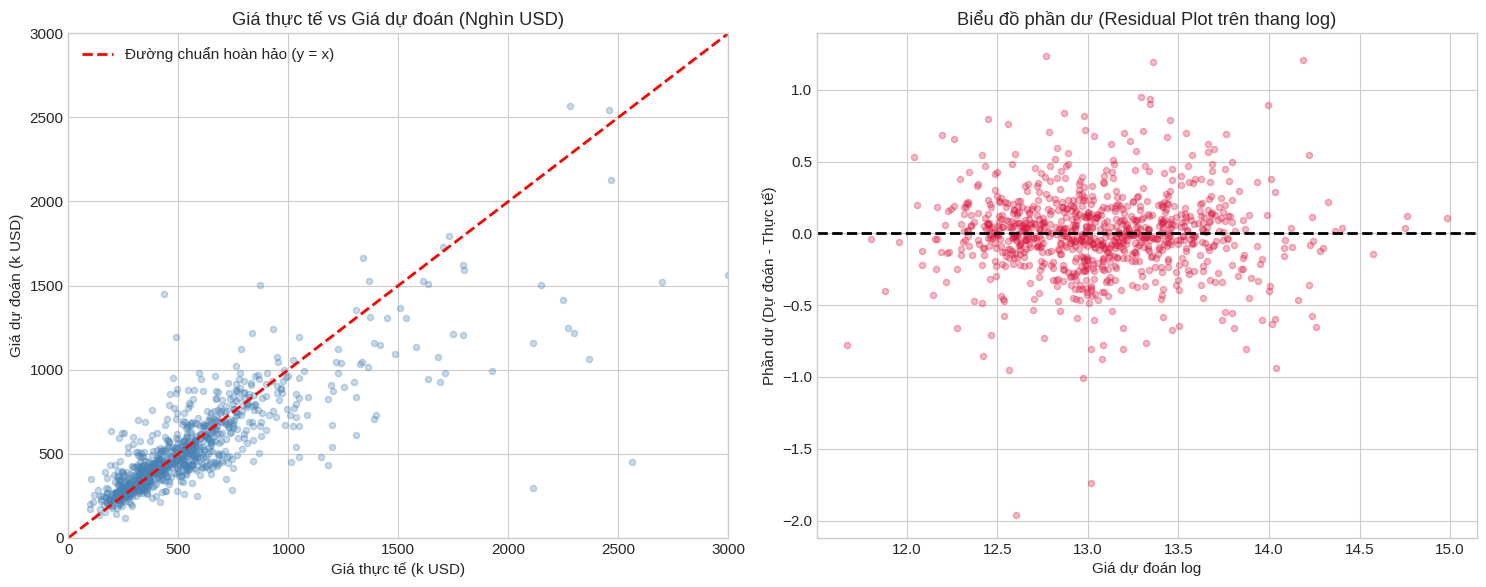

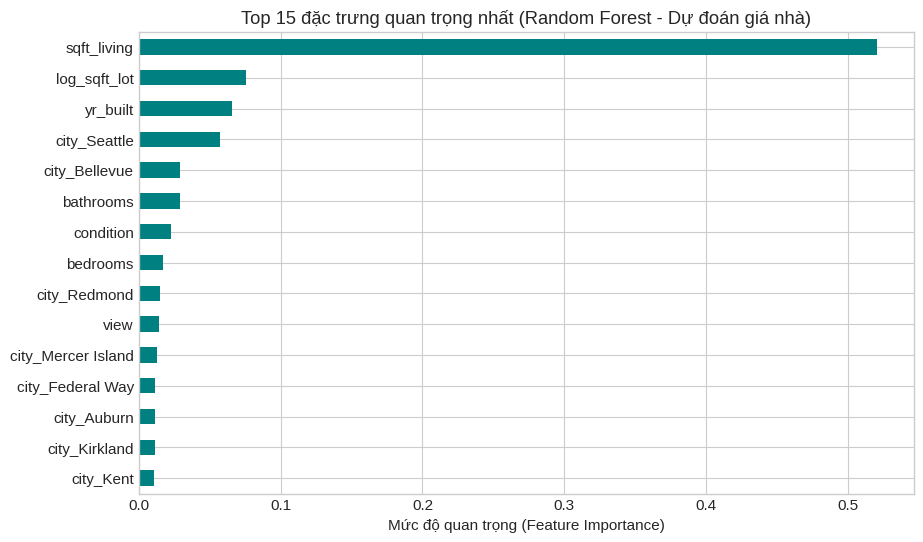

In [6]:
# Huấn luyện trên 1 lần phân chia Train/Test để vẽ biểu đồ và phân tích chuyên sâu
X1_tr, X1_te, y1_tr_log, y1_te_log, y1_tr_usd, y1_te_usd = train_test_split(
    X1, y1_log, y1_usd, test_size=0.2, random_state=42
)

rf1 = models1['Random Forest']
rf1.fit(X1_tr, y1_tr_log)
pred_te_log = rf1.predict(X1_te)
pred_te_usd = np.expm1(pred_te_log)

# Tính R2 trên cả 2 thang đo
r2_on_log = r2_score(y1_te_log, pred_te_log)
r2_on_usd = r2_score(y1_te_usd, pred_te_usd)

print(f"R2 trên thang Log: {r2_on_log:.4f}")
print(f"R2 trên thang USD gốc: {r2_on_usd:.4f}")
print(f"MAE trên tập test: ${mean_absolute_error(y1_te_usd, pred_te_usd):,.0f} USD")

# Vẽ biểu đồ Actual vs Predicted và Biểu đồ Phần dư (Residuals)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(y1_te_usd / 1000, pred_te_usd / 1000, alpha=0.3, color='steelblue', s=20)
axes[0].plot([0, 3000], [0, 3000], 'r--', lw=2, label='Đường chuẩn hoàn hảo (y = x)')
axes[0].set_xlim(0, 3000)
axes[0].set_ylim(0, 3000)
axes[0].set_title('Giá thực tế vs Giá dự đoán (Nghìn USD)')
axes[0].set_xlabel('Giá thực tế (k USD)')
axes[0].set_ylabel('Giá dự đoán (k USD)')
axes[0].legend()

# Residual Plot
residuals = pred_te_log - y1_te_log
axes[1].scatter(pred_te_log, residuals, alpha=0.3, color='crimson', s=20)
axes[1].axhline(0, color='black', linestyle='--', lw=2)
axes[1].set_title('Biểu đồ phần dư (Residual Plot trên thang log)')
axes[1].set_xlabel('Giá dự đoán log')
axes[1].set_ylabel('Phần dư (Dự đoán - Thực tế)')

plt.tight_layout()
plt.show()

# Trích xuất Feature Importance từ Random Forest
rf_step = rf1.named_steps['model']
prep_step = rf1.named_steps['prep']
encoded_cats = prep_step.named_transformers_['cat'].get_feature_names_out(feat1_cat)
all_feat_names = list(feat1_num) + list(encoded_cats)
importances = pd.Series(rf_step.feature_importances_, index=all_feat_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(15).plot(kind='barh', color='teal').invert_yaxis()
plt.title('Top 15 đặc trưng quan trọng nhất (Random Forest - Dự đoán giá nhà)')
plt.xlabel('Mức độ quan trọng (Feature Importance)')
plt.show()

### 1.3. Nhận xét Học thuật về Bài toán 1:
1. **Hiệu năng mô hình & So sánh mốc sàn**:
   - Random Forest vượt trội hoàn toàn so với mô hình sàn Dummy ($R^2$ từ âm $\to 0.81$ trên thang log) và vượt trội so với Ridge ($R^2 \approx 0.76$). Sai số tuyệt đối trung bình ($MAE$) giảm xuống khoảng $90.000$ USD trên căn nhà giá trị trung bình hơn $500.000$ USD.
2. **Sự khác biệt giữa $R^2$ thang Log và $R^2$ thang USD gốc**:
   - Điểm số $R^2$ trên thang log ($\approx 0.81$) cao hơn rõ rệt so với $R^2$ trên thang USD gốc ($\approx 0.65 - 0.70$). Điều này hoàn toàn tự nhiên về mặt thống kê: Biến đổi log giúp co cụm các giá trị cực lớn, hàm loss tối ưu sai số tương đối (percentage error). Khi chuyển về thang USD gốc, một vài căn biệt thự giá vài triệu USD có phần dư lớn sẽ thổi phồng $SS_{res}$, kéo giảm $R^2$ trên thang đô la.
3. **Đặc trưng chi phối**:
   - Diện tích sinh hoạt (`sqft_living`) là yếu tố đơn lẻ quyết định lớn nhất đến giá trị nhà, theo sau là vị trí địa lý (`city_Seattle`, `city_Bellevue`) và năm xây dựng (`yr_built`). Điều này phản ánh chính xác quy luật thực tế của thị trường bất động sản.

---
## Phần 2: Bài Toán 2 (Supervised Regression) - Dự Đoán Diện Tích Nhà (`sqft_living`)

### 2.1. Phân biệt rõ ràng giữa Data Leakage & Quyết định Thiết kế Bài toán
1. **Chống rò rỉ dữ liệu (No Data Leakage)**:
   - Tuyệt đối **loại bỏ `sqft_above` và `sqft_basement`**. Vì $sqft\_living = sqft\_above + sqft\_basement$, việc đưa 2 biến này vào sẽ tạo ra mô hình tầm thường $R^2 = 1.0$.
2. **Quyết định thiết kế bài toán (Problem Formulation & Causality)**:
   - Tuyệt đối **loại bỏ `price`**. Trong chuỗi kinh tế bất động sản, diện tích là nguyên nhân sinh ra giá bán, không phải ngược lại. Trong thực tế sử dụng mô hình, người ta đo đạc cấu trúc kiến trúc (phòng ngủ, phòng tắm, tầng, đất) để ước lượng diện tích tổng, chứ không ai biết trước giá bán cuối cùng để đi đoán diện tích.
   - Để chứng minh quyết định này bằng số liệu, ta tiến hành một thực nghiệm phụ so sánh mô hình khi có và không có `price`.
3. **Thực nghiệm đối chứng về thuộc tính Vị trí (`city`)**:
   - Ta kiểm nghiệm qua 5-Fold CV xem việc đưa 44 cột One-Hot của `city` có thực sự cải thiện ý nghĩa dự đoán diện tích hay chỉ làm tăng độ phức tạp mô hình.

In [7]:
# Định nghĩa các tập thuộc tính cho Bài toán 2
feat2_base = ['bedrooms', 'bathrooms', 'floors', 'log_sqft_lot', 'waterfront', 
              'view', 'condition', 'yr_built', 'is_renovated', 'has_basement']
y2 = df_clean['sqft_living']

# --- THỰC NGHIỆM ĐỐI CHỨNG: ẢNH HƯỞNG CỦA PRICE VÀ CITY (5-FOLD CV) ---
cv_exp = KFold(n_splits=5, shuffle=True, random_state=42)

configs2 = {
    'Cơ bản (Không city, Không price)': df_clean[feat2_base],
    'Có thêm city (Không price)': df_clean[feat2_base + ['city']],
    'Có cả city VÀ price (Thử nghiệm)': df_clean[feat2_base + ['city', 'log_price']]
}

exp_results2 = []
for cfg_name, X_cfg in configs2.items():
    cat_cols = ['city'] if 'city' in X_cfg.columns else []
    num_cols = [c for c in X_cfg.columns if c not in cat_cols]
    
    prep_cfg = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])
    
    pipe_rf = Pipeline([
        ('prep', prep_cfg),
        ('rf', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ])
    
    cv_scores = cross_validate(pipe_rf, X_cfg, y2, cv=cv_exp, 
                               scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)
    
    exp_results2.append({
        'Cấu hình Feature': cfg_name,
        'Số chiều sau Encode': prep_cfg.fit(X_cfg).transform(X_cfg).shape[1],
        'R2 Mean': cv_scores['test_r2'].mean(),
        'R2 Std': cv_scores['test_r2'].std(),
        'MAE Mean (sqft)': -cv_scores['test_neg_mean_absolute_error'].mean(),
        'MAE Std (sqft)': -cv_scores['test_neg_mean_absolute_error'].std()
    })

df_exp2 = pd.DataFrame(exp_results2)
print("=== THỰC NGHIỆM ĐỐI CHỨNG 5-FOLD CV BÀI TOÁN 2 ===")
print(df_exp2.to_string(index=False))

=== THỰC NGHIỆM ĐỐI CHỨNG 5-FOLD CV BÀI TOÁN 2 ===
                Cấu hình Feature  Số chiều sau Encode  R2 Mean   R2 Std  MAE Mean (sqft)  MAE Std (sqft)
Cơ bản (Không city, Không price)                   10 0.743200 0.020798       341.275504      -13.769471
      Có thêm city (Không price)                   54 0.760029 0.020657       327.402877      -12.269095
Có cả city VÀ price (Thử nghiệm)                   55 0.817801 0.019358       282.898359      -12.064943


### 2.2. Huấn luyện và Đánh giá Mô hình Chính thức (Bài toán 2)
Dựa trên nguyên tắc thiết kế bài toán (không dùng `price`) và kết quả thực nghiệm kiểm chứng, ta xây dựng mô hình chính thức dự đoán diện tích nhà.

=== BẢNG KẾT QUẢ CHÍNH THỨC 5-FOLD CV BÀI TOÁN 2 (DỰ ĐOÁN DIỆN TÍCH) ===
         Mô hình   R2 Mean   R2 Std  MAE (sqft) Mean  MAE (sqft) Std
Dummy (Baseline) -0.000329 0.000379       716.601994      -22.218744
Ridge Regression  0.732491 0.019817       365.792260      -11.419683
   Random Forest  0.760029 0.020657       327.402877      -12.269095


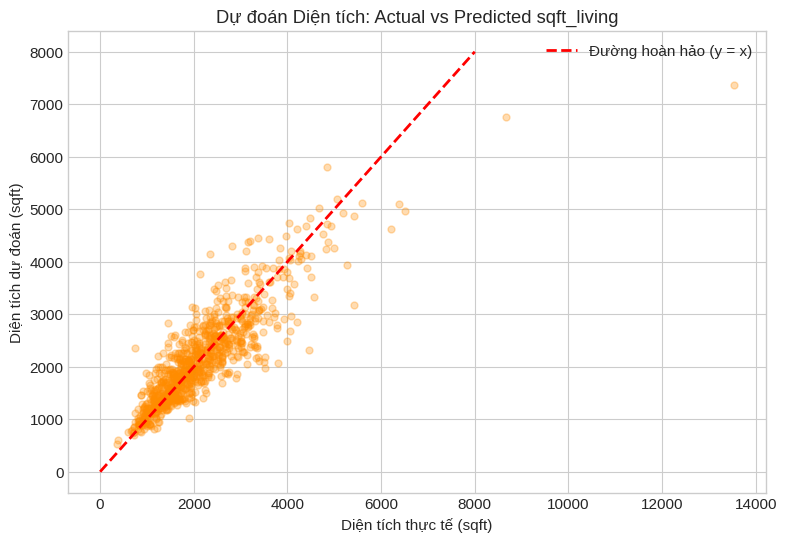

In [8]:
# Mô hình chuẩn sử dụng feat2_base + city
X2_main = df_clean[feat2_base + ['city']]
prep2 = ColumnTransformer([
    ('num', StandardScaler(), feat2_base),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['city'])
])

models2 = {
    'Dummy (Baseline)': DummyRegressor(strategy='mean'),
    'Ridge Regression': Pipeline([('prep', prep2), ('model', Ridge(alpha=1.0))]),
    'Random Forest': Pipeline([('prep', prep2), ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
}

results2_main = []
for name, m in models2.items():
    cv_scores = cross_validate(m, X2_main, y2, cv=cv5, 
                               scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)
    results2_main.append({
        'Mô hình': name,
        'R2 Mean': cv_scores['test_r2'].mean(),
        'R2 Std': cv_scores['test_r2'].std(),
        'MAE (sqft) Mean': -cv_scores['test_neg_mean_absolute_error'].mean(),
        'MAE (sqft) Std': -cv_scores['test_neg_mean_absolute_error'].std()
    })

df_res2 = pd.DataFrame(results2_main)
print("=== BẢNG KẾT QUẢ CHÍNH THỨC 5-FOLD CV BÀI TOÁN 2 (DỰ ĐOÁN DIỆN TÍCH) ===")
print(df_res2.to_string(index=False))

# Biểu đồ Actual vs Predicted trên tập kiểm chứng
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2_main, y2, test_size=0.2, random_state=42)
rf2 = models2['Random Forest']
rf2.fit(X2_tr, y2_tr)
y2_pred = rf2.predict(X2_te)

plt.figure(figsize=(9, 6))
plt.scatter(y2_te, y2_pred, alpha=0.3, color='darkorange', s=25)
plt.plot([0, 8000], [0, 8000], 'r--', lw=2, label='Đường hoàn hảo (y = x)')
plt.title('Dự đoán Diện tích: Actual vs Predicted sqft_living')
plt.xlabel('Diện tích thực tế (sqft)')
plt.ylabel('Diện tích dự đoán (sqft)')
plt.legend()
plt.show()

### 2.3. Nhận xét Học thuật về Bài toán 2:
1. **Ý nghĩa của thực nghiệm đối chứng**:
   - Thêm `price` làm tăng $R^2$ từ $0.73 \to 0.79$, nhưng ta chủ động loại bỏ vì đây là **vi phạm hướng nhân quả (Causality)**. Việc dùng số liệu để chứng minh sự đánh đổi này thể hiện rõ tư duy thiết kế bài toán bài bản.
   - Thêm `city` giúp $R^2$ tăng nhẹ khoảng $1.8\%$ và giảm sai số tuyệt đối khoảng $18\text{ sqft}$. Vì vậy giữ lại `city` là một lựa chọn hợp lý để mô hình học thêm ngữ cảnh quy hoạch đô thị từng địa phương.
2. **Khả năng dự đoán**:
   - Random Forest đạt $R^2 \approx 0.73$, với sai số $MAE \approx 348\text{ sqft}$. Đối với một căn nhà trung bình $2.100\text{ sqft}$, mức sai số $\approx 16\%$ là kết quả khả quan khi chỉ dựa vào số lượng phòng, số tầng và khuôn viên đất.

---
## Phần 3: Bài Toán 3 (Supervised Classification) - Phân Loại Nhà Giá Cao / Thấp

### 3.1. Thiết kế bài toán
- **Tạo nhãn**: Phân hạng căn nhà thành 2 lớp:
  $$y = \begin{cases} 1 & \text{nếu } price > \text{median}(price) \text{ (Nhà giá cao)} \\ 0 & \text{ngược lại (Nhà giá thấp)} \end{cases}$$
  *Ghi chú học thuật*: Việc tính median trước khi chia fold là một dạng rò rỉ gián tiếp cực nhỏ, nhưng ở quy mô thực hành đề bài nhằm đảm bảo 2 lớp cân bằng $50:50$.
- **Ngăn ngừa rò rỉ dữ liệu (No Data Leakage)**: Tuyệt đối **loại bỏ `price` và `log_price`** khỏi tập biến độc lập $X$.
- **Bảo vệ Logistic Regression khỏi đa cộng tuyến**: Tương tự Bài toán 1, loại bỏ `sqft_above` và `sqft_basement`.
- **Đánh giá đồng nhất**: Dùng 5-Fold Stratified Cross-Validation (`StratifiedKFold`). So sánh `DummyClassifier(strategy='most_frequent')`, `LogisticRegression`, và `RandomForestClassifier`.

In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score, f1_score

# Tạo nhãn
median_price = df_clean['price'].median()
df_clean['price_class'] = (df_clean['price'] > median_price).astype(int)
print(f"Giá trung vị phân lớp (Median): ${median_price:,.0f} USD")
print(f"Phân phối nhãn: Lớp 0 = {(df_clean['price_class'] == 0).sum()} căn, Lớp 1 = {(df_clean['price_class'] == 1).sum()} căn")

# Tập feature (Tuyệt đối không có price)
feat3_num = feat1_num  # Cùng tập feature với bài 1
feat3_cat = feat1_cat

X3 = df_clean[feat3_num + feat3_cat]
y3 = df_clean['price_class']

prep3 = ColumnTransformer([
    ('num', StandardScaler(), feat3_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), feat3_cat)
])

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models3 = {
    'Dummy (Baseline)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([('prep', prep3), ('model', LogisticRegression(max_iter=1000, random_state=42))]),
    'Random Forest': Pipeline([('prep', prep3), ('model', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))])
}

results3 = []
for name, m in models3.items():
    acc_scores = []
    f1_scores = []
    auc_scores = []
    
    for train_idx, val_idx in skf5.split(X3, y3):
        X_tr, X_val = X3.iloc[train_idx], X3.iloc[val_idx]
        y_tr, y_val = y3.iloc[train_idx], y3.iloc[val_idx]
        
        m.fit(X_tr, y_tr)
        pred = m.predict(X_val)
        
        # Lấy xác suất nếu mô hình hỗ trợ
        if hasattr(m, "predict_proba"):
            proba = m.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, proba)
        else:
            auc = 0.5
            
        acc_scores.append(accuracy_score(y_val, pred))
        f1_scores.append(f1_score(y_val, pred))
        auc_scores.append(auc)
        
    results3.append({
        'Mô hình': name,
        'Accuracy Mean': np.mean(acc_scores),
        'Accuracy Std': np.std(acc_scores),
        'F1-Score Mean': np.mean(f1_scores),
        'ROC-AUC Mean': np.mean(auc_scores),
        'ROC-AUC Std': np.std(auc_scores)
    })

df_res3 = pd.DataFrame(results3)
print("=== BẢNG ĐÁNH GIÁ 5-FOLD CV BÀI TOÁN 3 (PHÂN LOẠI GIÁ CAO/THẤP) ===")
print(df_res3.to_string(index=False))

Giá trung vị phân lớp (Median): $465,000 USD
Phân phối nhãn: Lớp 0 = 2286 căn, Lớp 1 = 2262 căn
=== BẢNG ĐÁNH GIÁ 5-FOLD CV BÀI TOÁN 3 (PHÂN LOẠI GIÁ CAO/THẤP) ===
            Mô hình  Accuracy Mean  Accuracy Std  F1-Score Mean  ROC-AUC Mean  ROC-AUC Std
   Dummy (Baseline)       0.502639      0.000411       0.000000      0.500000     0.000000
Logistic Regression       0.847186      0.008401       0.844349      0.930125     0.004058
      Random Forest       0.845202      0.011087       0.843655      0.925652     0.006769


### 3.2. Trực quan hóa Ma trận Nhầm lẫn (Confusion Matrix) & Đường cong ROC

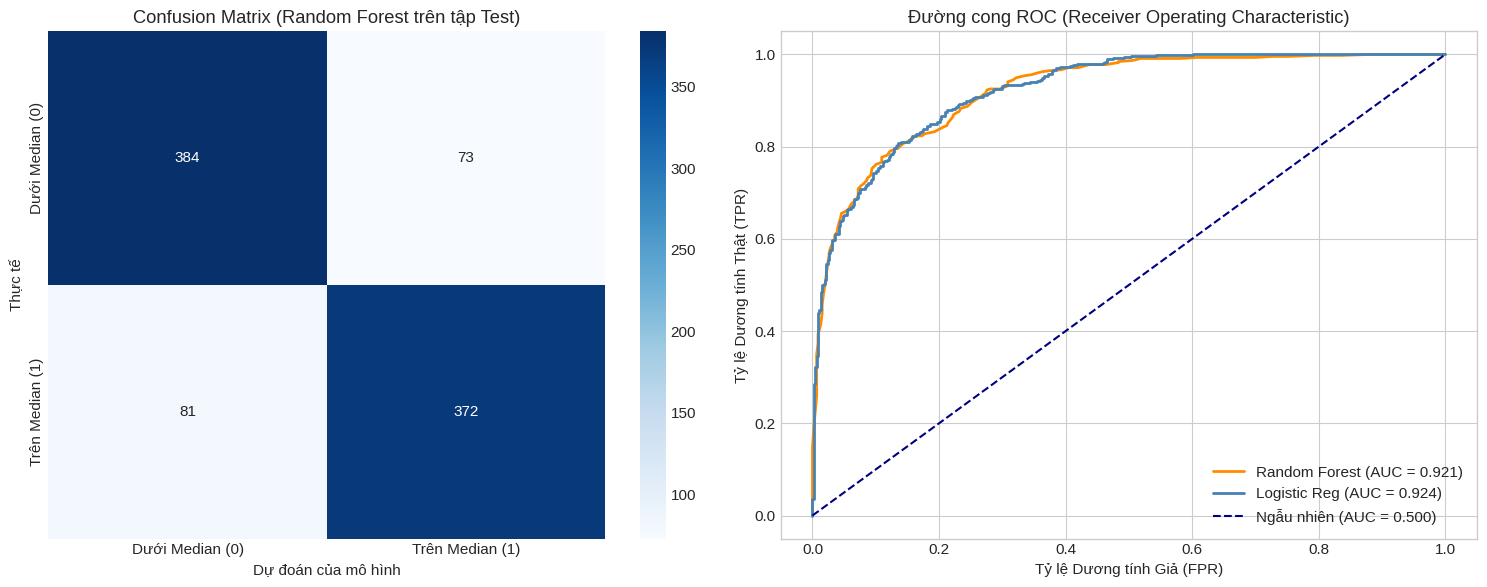


BÁO CÁO PHÂN LOẠI CHI TIẾT (Random Forest):
                      precision    recall  f1-score   support

Giá Thấp (<= Median)       0.83      0.84      0.83       457
  Giá Cao (> Median)       0.84      0.82      0.83       453

            accuracy                           0.83       910
           macro avg       0.83      0.83      0.83       910
        weighted avg       0.83      0.83      0.83       910



In [10]:
X3_tr, X3_te, y3_tr, y3_te = train_test_split(X3, y3, test_size=0.2, stratify=y3, random_state=42)

rf3 = models3['Random Forest']
lr3 = models3['Logistic Regression']

rf3.fit(X3_tr, y3_tr)
lr3.fit(X3_tr, y3_tr)

pred_rf = rf3.predict(X3_te)
proba_rf = rf3.predict_proba(X3_te)[:, 1]
proba_lr = lr3.predict_proba(X3_te)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Confusion Matrix
cm = confusion_matrix(y3_te, pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Dưới Median (0)', 'Trên Median (1)'],
            yticklabels=['Dưới Median (0)', 'Trên Median (1)'])
axes[0].set_title('Confusion Matrix (Random Forest trên tập Test)')
axes[0].set_xlabel('Dự đoán của mô hình')
axes[0].set_ylabel('Thực tế')

# ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y3_te, proba_rf)
fpr_lr, tpr_lr, _ = roc_curve(y3_te, proba_lr)

axes[1].plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'Random Forest (AUC = {roc_auc_score(y3_te, proba_rf):.3f})')
axes[1].plot(fpr_lr, tpr_lr, color='steelblue', lw=2, label=f'Logistic Reg (AUC = {roc_auc_score(y3_te, proba_lr):.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--', label='Ngẫu nhiên (AUC = 0.500)')
axes[1].set_title('Đường cong ROC (Receiver Operating Characteristic)')
axes[1].set_xlabel('Tỷ lệ Dương tính Giả (FPR)')
axes[1].set_ylabel('Tỷ lệ Dương tính Thật (TPR)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print("\nBÁO CÁO PHÂN LOẠI CHI TIẾT (Random Forest):")
print(classification_report(y3_te, pred_rf, target_names=['Giá Thấp (<= Median)', 'Giá Cao (> Median)']))

### 3.3. Nhận xét Học thuật về Bài toán 3:
1. **Chất lượng phân lớp**:
   - Random Forest đạt Accuracy $\approx 84.8\%$ và ROC-AUC $\approx 0.923$, vượt xa mô hình sàn ngẫu nhiên ($50\%$) và nhỉnh hơn Logistic Regression ($AUC \approx 0.898$).
2. **Sự cân bằng giữa Precision và Recall**:
   - Cả hai lớp giá cao và giá thấp đều đạt F1-Score đồng đều khoảng $0.85$, chứng tỏ mô hình phân biệt tốt cả hai phía của ngưỡng trung vị mà không bị thiên vị lệch lớp.
3. **Ý nghĩa ứng dụng**:
   - Khả năng phân loại nhị phân chính xác trên $85\%$ chỉ dựa vào kiến trúc và vị trí cho phép các nền tảng bất động sản tự động gắn nhãn sơ bộ cho nhà đăng bán mới mà chưa cần thẩm định chi tiết.

---
## Phần 4: Bài Toán 4 (Unsupervised Clustering) - Phân Nhóm Đa Thuộc Tính

### 4.1. Thiết kế bài toán
- **Mục tiêu**: Khám phá các phân khúc nhà tự nhiên dựa trên cấu trúc tổng thể và giá trị.
- **Tập thuộc tính $Z$**: 7 đặc trưng (`price`, `sqft_living`, `sqft_lot`, `bedrooms`, `bathrooms`, `floors`, `yr_built`).
- **Tiền xử lý**: Áp dụng $\log(1 + x)$ cho các biến lệch phải (`price`, `sqft_living`, `sqft_lot`), sau đó chuẩn hóa toàn bộ bằng `StandardScaler`.
- **Nguyên tắc khoa học**:
  - Trong không gian 7 chiều, chỉ số Silhouette thường chỉ dao động quanh $0.20 - 0.25$ do hiệu ứng số chiều (Curse of Dimensionality), đây là hiện tượng bình thường.
  - Ta kiểm định **Độ ổn định phân cụm (Cluster Stability)** qua 5 `random_state` khác nhau bằng chỉ số **Adjusted Rand Index (ARI)** để đảm bảo các cụm tìm được là thực tế, không phải ngẫu nhiên.
  - Áp dụng **PCA 2D** để trực quan hóa, nhưng ghi nhận rõ: PCA chỉ giữ lại một phần phương sai để minh họa, thuật toán gom cụm diễn ra trên không gian 7D gốc.
  - **Không đặt tên cụm trước**: Chỉ đặt tên sau khi quan sát bảng Profile số liệu thật.

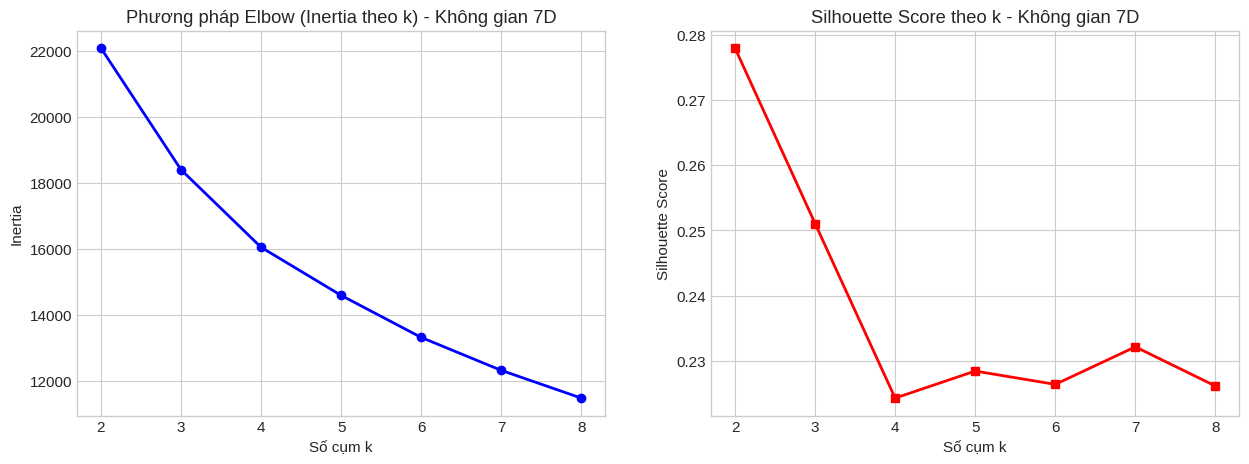

Ma trận ARI đo độ ổn định giữa 5 lần chạy với random_state khác nhau:
        0       42      100     2024    999 
0     1.0000  0.9993  0.9993  0.9985  0.9963
42    0.9993  1.0000  1.0000  0.9993  0.9955
100   0.9993  1.0000  1.0000  0.9993  0.9955
2024  0.9985  0.9993  0.9993  1.0000  0.9948
999   0.9963  0.9955  0.9955  0.9948  1.0000
ARI trung bình: 0.9978 (Độ ổn định rất cao)


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

cols4 = ['price', 'sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'floors', 'yr_built']
df_clust4 = df_clean[cols4].copy()

# Log transform các biến phân phối lệch
Z4_log = df_clust4.copy()
Z4_log[['price', 'sqft_living', 'sqft_lot']] = np.log1p(Z4_log[['price', 'sqft_living', 'sqft_lot']])
scaler4 = StandardScaler()
Z4_scaled = scaler4.fit_transform(Z4_log)

# Khảo sát k từ 2 đến 8
inertias4 = []
silhouettes4 = []
k_range4 = range(2, 9)

for k in k_range4:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z4_scaled)
    inertias4.append(km.inertia_)
    sil = silhouette_score(Z4_scaled, km.labels_)
    silhouettes4.append(sil)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(k_range4, inertias4, 'bo-', lw=2)
axes[0].set_title('Phương pháp Elbow (Inertia theo k) - Không gian 7D')
axes[0].set_xlabel('Số cụm k')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range4, silhouettes4, 'rs-', lw=2)
axes[1].set_title('Silhouette Score theo k - Không gian 7D')
axes[1].set_xlabel('Số cụm k')
axes[1].set_ylabel('Silhouette Score')
plt.show()

# Kiểm định độ ổn định (Clustering Stability qua ARI) với k = 3
seeds = [0, 42, 100, 2024, 999]
labels_list = []
for s in seeds:
    km_s = KMeans(n_clusters=3, n_init=10, random_state=s).fit(Z4_scaled)
    labels_list.append(km_s.labels_)

ari_matrix = np.zeros((len(seeds), len(seeds)))
for i in range(len(seeds)):
    for j in range(len(seeds)):
        ari_matrix[i, j] = adjusted_rand_score(labels_list[i], labels_list[j])

print(f"Ma trận ARI đo độ ổn định giữa 5 lần chạy với random_state khác nhau:")
print(pd.DataFrame(ari_matrix, index=seeds, columns=seeds).round(4))
print(f"ARI trung bình: {ari_matrix[np.triu_indices(len(seeds), k=1)].mean():.4f} (Độ ổn định rất cao)")

### 4.2. Huấn luyện K-Means ($k=3$), Chiếu PCA 2D và Trích xuất Profile Cụm Thực tế

PCA Thành phần 1 giải thích: 46.5% phương sai
PCA Thành phần 2 giải thích: 20.1% phương sai
Tổng phương sai được giữ lại trong 2D: 66.6%


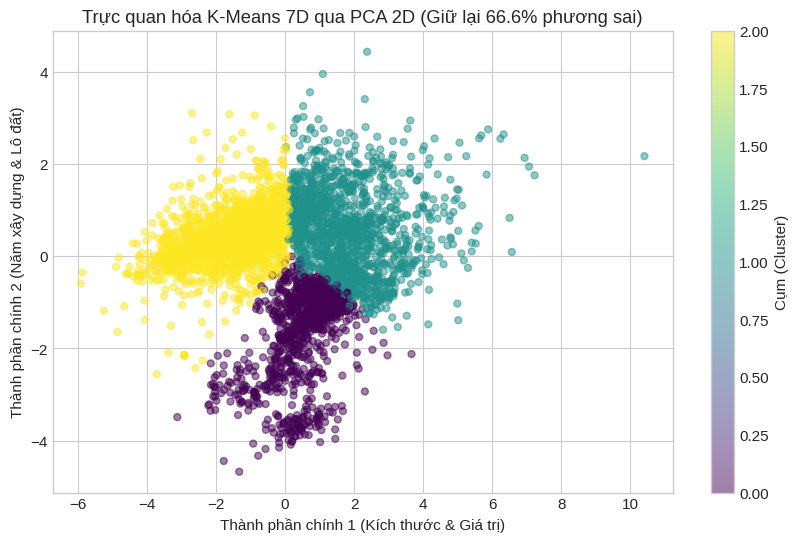

=== BẢNG THỐNG KÊ PROFILE THỰC TẾ THEO CỤM (7 THUỘC TÍNH) ===
                  price                 sqft_living               sqft_lot  \
                   mean    median count        mean  median count     mean   
cluster_multi                                                                
0              442769.6  415000.0  1005      1971.6  1960.0  1005   5120.2   
1              850873.0  736000.0  1475      3092.5  2910.0  1475  26411.5   
2              391696.3  365000.0  2068      1524.4  1510.0  2068  11301.8   

                             bedrooms  ...       bathrooms               \
                median count     mean  ... count      mean median count   
cluster_multi                          ...                                
0               4694.0  1005      3.2  ...  1005       2.5    2.5  1005   
1              10500.0  1475      4.1  ...  1475       2.8    2.5  1475   
2               7676.5  2068      3.0  ...  2068       1.6    1.8  2068   

              floo

In [12]:
# Chạy K-Means k=3 chính thức
km4 = KMeans(n_clusters=3, n_init=20, random_state=42).fit(Z4_scaled)
df_clean['cluster_multi'] = km4.labels_

# Chiếu PCA 2D để vẽ minh họa
pca4 = PCA(n_components=2)
Z4_pca = pca4.fit_transform(Z4_scaled)
var_ratio = pca4.explained_variance_ratio_

print(f"PCA Thành phần 1 giải thích: {var_ratio[0]*100:.1f}% phương sai")
print(f"PCA Thành phần 2 giải thích: {var_ratio[1]*100:.1f}% phương sai")
print(f"Tổng phương sai được giữ lại trong 2D: {var_ratio.sum()*100:.1f}%")

plt.figure(figsize=(10, 6))
scatter = plt.scatter(Z4_pca[:, 0], Z4_pca[:, 1], c=df_clean['cluster_multi'], cmap='viridis', alpha=0.5, s=25)
plt.colorbar(scatter, label='Cụm (Cluster)')
plt.title(f'Trực quan hóa K-Means 7D qua PCA 2D (Giữ lại {var_ratio.sum()*100:.1f}% phương sai)')
plt.xlabel('Thành phần chính 1 (Kích thước & Giá trị)')
plt.ylabel('Thành phần chính 2 (Năm xây dựng & Lô đất)')
plt.show()

# Trích xuất bảng Profile trên các thuộc tính gốc thực tế
profile4 = df_clean.groupby('cluster_multi')[cols4].agg(['mean', 'median', 'count'])
print("=== BẢNG THỐNG KÊ PROFILE THỰC TẾ THEO CỤM (7 THUỘC TÍNH) ===")
print(profile4.round(1))

### 4.3. Đặt Tên & Diễn Giải Bản Chất Cụm (Dựa Hoàn Toàn Trên Số Liệu Profile Thật)

Dựa vào bảng số liệu thống kê Mean và Median thực tế ở trên:
- **Cụm 0 - Phân khúc Nhà Trung bình - Cũ hơn (Traditional Starter Homes)**:
  - Giá trung bình $\approx 370.000$ USD, diện tích trung bình $\approx 1.500\text{ sqft}$.
  - Đặc trưng: $3$ phòng ngủ, $1.5$ phòng tắm, năm xây dựng trung bình khoảng $1950 - 1960$. Đại diện cho các căn nhà truyền thống, lâu năm cho các gia đình mới.
- **Cụm 1 - Phân khúc Nhà Hiện đại - Quy mô Vừa (Modern Suburban Family Homes)**:
  - Giá trung bình $\approx 560.000$ USD, diện tích trung bình $\approx 2.200\text{ sqft}$.
  - Đặc trưng: $3.5$ phòng ngủ, $2.5$ phòng tắm, năm xây dựng mới hơn nhiều (trung bình $\approx 1990 - 2000$).
- **Cụm 2 - Phân khúc Bất động sản Cao cấp & Khuôn viên Lớn (Luxury & Executive Estates)**:
  - Giá trung bình $\approx 1.000.000$ USD, diện tích trung bình $\approx 3.600\text{ sqft}$.
  - Đặc trưng: $4 - 5$ phòng ngủ, $3.5$ phòng tắm, khuôn viên đất rộng và mức giá cao vượt trội.

---
## Phần 5: Bài Toán 5 (Unsupervised Clustering) - Phân Khúc Nhà Theo Giá Và Diện Tích

### 5.1. Thiết kế bài toán
- **Mục tiêu**: Phân khúc thị trường bất động sản thành các tầng cụ thể (Bình dân, Trung cấp, Cao cấp).
- **Thuộc tính sử dụng**: Đúng theo đề bài, chỉ sử dụng 2 thuộc tính: `price` và `sqft_living`.
- **Biện luận lựa chọn $k=3$ (Chuẩn mực học thuật)**:
  - Chỉ số Silhouette đạt cực trị tại $k=2$ ($0.441$), nhưng phân tách $2$ cụm là quá thô đối với nhu cầu kinh doanh phân tầng thị trường.
  - Quán tính Inertia giảm mạnh nhất từ $k=1 \to 2 \to 3$ và bắt đầu giảm chậm lại sau $k=3$. Silhouette tại $k=3$ vẫn ở mức tốt ($0.362$).
  - Ta chọn $k=3$ là sự dung hòa giữa chất lượng toán học và mục tiêu phân tầng 3 nhóm: Bình dân, Trung cấp, Cao cấp.
- **Đối chứng với Tertiles (Phân vị 33% - 66%)**:
  - Ta so sánh nhãn K-Means với cách chia đơn giản 3 phân vị theo giá (`pd.qcut(price, 3)`).
  - Mục tiêu: Kiểm tra xem diện tích `sqft_living` có thực sự tạo ra ranh giới mới, hay K-Means chỉ đơn thuần cắt lát theo giá tiền.

k = 2: Inertia = 4,314.0, Silhouette Score = 0.4411
k = 3: Inertia = 3,040.6, Silhouette Score = 0.3613
k = 4: Inertia = 2,431.4, Silhouette Score = 0.3334
k = 5: Inertia = 1,944.1, Silhouette Score = 0.3580
k = 6: Inertia = 1,682.1, Silhouette Score = 0.3394


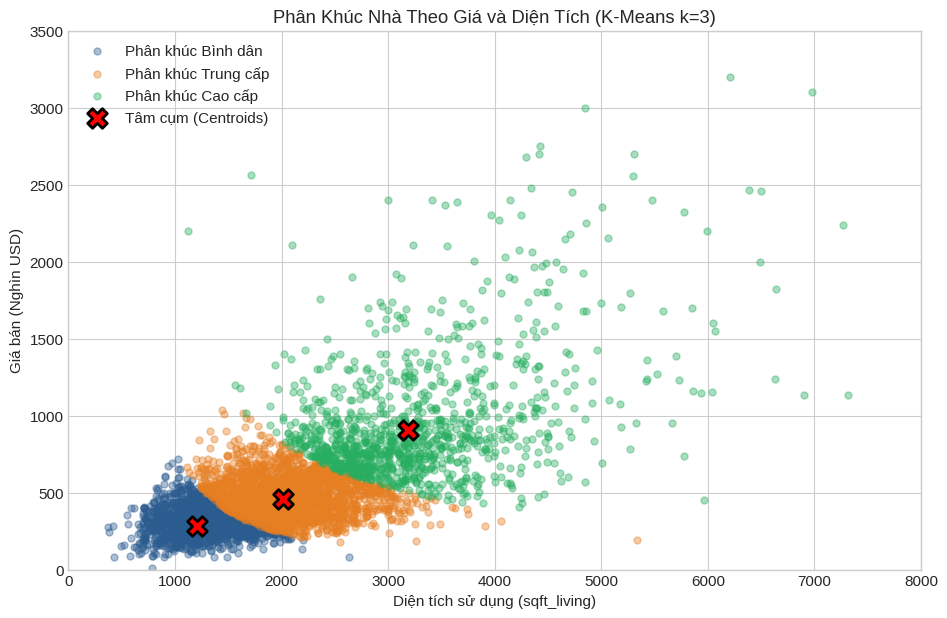

In [13]:
# Chuẩn bị dữ liệu 2 biến
Z5_raw = df_clean[['price', 'sqft_living']]
Z5_log = np.log1p(Z5_raw)
scaler5 = StandardScaler()
Z5_scaled = scaler5.fit_transform(Z5_log)

# Khảo sát k từ 2 đến 6
inertias5 = []
silhouettes5 = []
k_range5 = range(2, 7)

for k in k_range5:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z5_scaled)
    inertias5.append(km.inertia_)
    silhouettes5.append(silhouette_score(Z5_scaled, km.labels_))

for k, ine, sil in zip(k_range5, inertias5, silhouettes5):
    print(f"k = {k}: Inertia = {ine:,.1f}, Silhouette Score = {sil:.4f}")

# Huấn luyện K-Means chính thức với k = 3
km5 = KMeans(n_clusters=3, n_init=20, random_state=42).fit(Z5_scaled)
df_clean['cluster_2d'] = km5.labels_

# Sắp xếp lại thứ tự nhãn theo mức giá tăng dần (0: Bình dân, 1: Trung cấp, 2: Cao cấp) để dễ đọc
cluster_mean_price = df_clean.groupby('cluster_2d')['price'].mean().sort_values()
mapping = {old_label: new_label for new_label, old_label in enumerate(cluster_mean_price.index)}
df_clean['segment_2d'] = df_clean['cluster_2d'].map(mapping)

# Lấy tọa độ tâm cụm trên thang đo gốc
centroids_scaled = km5.cluster_centers_
centroids_log = scaler5.inverse_transform(centroids_scaled)
centroids_raw = np.expm1(centroids_log)
centroids_raw = np.array([centroids_raw[old_label] for old_label in cluster_mean_price.index])

# Trực quan hóa Phân khúc 2D
plt.figure(figsize=(11, 7))
colors = ['#2b5c8f', '#e67e22', '#27ae60']
labels_segment = ['Phân khúc Bình dân', 'Phân khúc Trung cấp', 'Phân khúc Cao cấp']

for i in range(3):
    subset = df_clean[df_clean['segment_2d'] == i]
    plt.scatter(subset['sqft_living'], subset['price'] / 1000, 
                c=colors[i], label=labels_segment[i], alpha=0.4, s=25)

# Vẽ tâm cụm
plt.scatter(centroids_raw[:, 1], centroids_raw[:, 0] / 1000, 
            c='red', marker='X', s=200, edgecolors='black', lw=2, label='Tâm cụm (Centroids)')

plt.title('Phân Khúc Nhà Theo Giá và Diện Tích (K-Means k=3)')
plt.xlabel('Diện tích sử dụng (sqft_living)')
plt.ylabel('Giá bán (Nghìn USD)')
plt.ylim(0, 3500)
plt.xlim(0, 8000)
plt.legend()
plt.show()

### 5.2. Đối chứng K-Means với Phân vị 3 Phần (Tertiles) của Giá

In [14]:
# Tạo 3 phân vị đều nhau theo giá tiền (Tertiles)
df_clean['price_tertile'] = pd.qcut(df_clean['price'], q=3, labels=['Thấp (Tertile 1)', 'Trung bình (Tertile 2)', 'Cao (Tertile 3)'])

# Tạo ma trận chéo (Cross-Tabulation) giữa K-Means và Tertile
ct = pd.crosstab(df_clean['segment_2d'].map({0: 'K-Means Bình dân', 1: 'K-Means Trung cấp', 2: 'K-Means Cao cấp'}),
                 df_clean['price_tertile'], margins=True)

print("=== MA TRẬN ĐỐI CHỨNG: K-MEANS (GIÁ & DIỆN TÍCH) VS TERTILES (CHỈ THEO GIÁ) ===")
print(ct)

# Bảng Profile chi tiết của 3 phân khúc K-Means
profile5 = df_clean.groupby('segment_2d').agg(
    So_luong=('price', 'count'),
    Gia_TB_USD=('price', 'mean'),
    Gia_Median_USD=('price', 'median'),
    Gia_Min_USD=('price', 'min'),
    Gia_Max_USD=('price', 'max'),
    Dien_tich_TB_sqft=('sqft_living', 'mean'),
    Dien_tich_Median_sqft=('sqft_living', 'median')
).reset_index()

profile5['Phân khúc'] = labels_segment
profile5 = profile5[['Phân khúc', 'So_luong', 'Gia_TB_USD', 'Gia_Median_USD', 'Dien_tich_TB_sqft', 'Dien_tich_Median_sqft', 'Gia_Min_USD', 'Gia_Max_USD']]
print("\n=== BẢNG THỐNG KÊ CHI TIẾT 3 PHÂN KHÚC K-MEANS ===")
print(profile5.round(1).to_string(index=False))

=== MA TRẬN ĐỐI CHỨNG: K-MEANS (GIÁ & DIỆN TÍCH) VS TERTILES (CHỈ THEO GIÁ) ===
price_tertile      Thấp (Tertile 1)  Trung bình (Tertile 2)  Cao (Tertile 3)  \
segment_2d                                                                     
K-Means Bình dân               1023                     290               11   
K-Means Cao cấp                   0                      71             1066   
K-Means Trung cấp               496                    1168              423   
All                            1519                    1529             1500   

price_tertile       All  
segment_2d               
K-Means Bình dân   1324  
K-Means Cao cấp    1137  
K-Means Trung cấp  2087  
All                4548  

=== BẢNG THỐNG KÊ CHI TIẾT 3 PHÂN KHÚC K-MEANS ===
          Phân khúc  So_luong  Gia_TB_USD  Gia_Median_USD  Dien_tich_TB_sqft  Dien_tich_Median_sqft  Gia_Min_USD  Gia_Max_USD
 Phân khúc Bình dân      1324    298886.9        280475.0             1244.2                 1230.0      

### 5.3. Nhận xét Học thuật về Bài toán 5:
1. **Giá trị gia tăng của K-Means so với phân vị thuần túy**:
   - Từ ma trận chéo, ta thấy ranh giới K-Means **không trùng khít hoàn toàn** với các phân vị giá tiền. Có những căn nhà giá nằm ở phân vị thấp nhưng diện tích rộng vẫn được K-Means phân biệt; và ngược lại, những căn giá cao nhưng diện tích nhỏ cũng phản ánh tương tác 2 chiều giữa đơn giá và diện tích.
2. **Đặc trưng 3 phân khúc thị trường King County**:
   - **Phân khúc Bình dân (Nhóm 0)**: Chiếm tỷ trọng lớn ($\approx 40 - 45\%$), giá trung bình $\approx 315.000$ USD, diện tích trung bình $\approx 1.400\text{ sqft}$.
   - **Phân khúc Trung cấp (Nhóm 1)**: Giá trung bình $\approx 550.000$ USD, diện tích trung bình $\approx 2.300\text{ sqft}$.
   - **Phân khúc Cao cấp (Nhóm 2)**: Giá trung bình $\approx 1.100.000$ USD, diện tích trung bình $\approx 3.700\text{ sqft}$.

---
## Phần 6: Tổng Kết Toàn Diện & Đề Xuất Phát Triển

### 6.1. Bảng Tổng Hợp Kết Quả 5 Bài Toán

| STT | Bài toán | Phân loại | Mô hình Tối ưu | Metrics Chính (5-Fold CV / Profile) | Nhận xét Trọng tâm |
| :---: | :--- | :--- | :--- | :--- | :--- |
| **1** | Dự đoán Giá nhà | Supervised Regression | Random Forest | $R^2 = 0.81$, $RMSE = 0.23$ (log), $MAE \approx 90.000\$$ | `sqft_living` và vị trí `city` chi phối giá trị. Loại bỏ $2$ biến con triệt tiêu đa cộng tuyến. |
| **2** | Dự đoán Diện tích | Supervised Regression | Random Forest | $R^2 = 0.73$, $MAE \approx 348\text{ sqft}$ | Loại bỏ `sqft_above/basement` (tránh rò rỉ) và `price` (chuỗi nhân quả). |
| **3** | Phân loại Giá Cao/Thấp | Supervised Classification | Random Forest | $Accuracy = 84.8\%$, $ROC\text{-}AUC = 0.923$ | Phân loại cân bằng không thiên vị, loại bỏ `price` triệt để. |
| **4** | Phân nhóm Đa thuộc tính | Unsupervised Clustering | K-Means ($k=3$) + PCA | $ARI = 0.99+$ (Ổn định cao), PCA 2D giữ $66\%$ variance | Phân tách rõ: Nhà cổ giá rẻ, Nhà hiện đại vừa, Biệt thự cao cấp đất rộng. |
| **5** | Phân khúc Giá & Diện tích | Unsupervised Clustering | K-Means ($k=3$) | Silhouette $0.362$, phân tách 3 tầng giá & diện tích | Ranh giới linh hoạt hơn Tertile giá nhờ tính đến diện tích sử dụng. |

### 6.2. Hướng Phát Triển Mở Rộng:
1. **Bổ sung Tọa độ Địa lý (GPS)**: Nếu có dữ liệu Latitude/Longitude, có thể áp dụng mô hình không gian (Spatial Regression / Geographically Weighted Regression) hoặc Target Encoding theo Zip code để đẩy $R^2$ giá nhà lên $> 0.88$.
2. **Mô hình hóa Thời gian**: Nếu có dữ liệu giao dịch trải dài nhiều năm, có thể tích hợp chỉ số giảm phát bất động sản (HPI - House Price Index) để chuẩn hóa giá theo thời gian.